# <font color='#BFD72F' size=6>**0. Imports**</font> <a class="anchor" id="1"></a>

[Back to TOC](#toc)

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

SEED = 42

# <font color='#BFD72F' size=6>**1. Data import**</font> <a class="anchor" id="1"></a>

[Back to TOC](#toc)

In [17]:
train = pd.read_csv("data/raw/train.csv")
test = pd.read_csv("data/raw/test.csv")
clientes = pd.read_csv("data/raw/clientes.csv")

### 1.1 Column-name standardisation

The raw CSV files are kept unchanged for traceability. We create standardised copies with lowercase English `snake_case` names for the reusable modelling pipeline; the existing exploratory cells continue to use the original raw labels.

In [18]:
import re
import unicodedata


english_column_names = {
    "Total a Pagar": "total_payable",
    "Total Bruto": "gross_total",
    "Total Liquido": "net_total",
    "Total Imp_": "total_tax",
    "Total Portes": "shipping_cost",
    "Total Desc_ Global": "global_discount_total",
    "Total Desc_ Linha": "line_discount_total",
    "Custo": "cost",
    "N_ Detalhes": "line_item_count",
    "ID": "record_id",
}


def to_snake_case(name):
    name = unicodedata.normalize("NFKD", str(name))
    name = name.encode("ascii", "ignore").decode("ascii")
    name = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    return re.sub(r"_+", "_", name)


def standardize_columns(df):
    clean_df = df.copy()
    clean_df.columns = [
        english_column_names.get(column, to_snake_case(column))
        for column in clean_df.columns
    ]
    if clean_df.columns.duplicated().any():
        raise ValueError("Column standardisation created duplicate names.")
    return clean_df


In [19]:
train_standardized = standardize_columns(train)
test_standardized = standardize_columns(test)
clientes_standardized = standardize_columns(clientes)

column_changes = pd.DataFrame({
    "original": train.columns,
    "standardized": train_standardized.columns,
})

display(column_changes.query("original != standardized"))
print("All standardized schemas have unique column names.")


,original,standardized
0,Total a Pagar,total_payable
1,Total Bruto,gross_total
2,Total Liquido,net_total
3,Total Imp_,total_tax
4,Total Portes,shipping_cost
5,Total Desc_ Global,global_discount_total
6,Total Desc_ Linha,line_discount_total
7,Custo,cost
8,N_ Detalhes,line_item_count
38,ID,record_id


All standardized schemas have unique column names.


# <font color='#BFD72F' size=6>**2. Missing values (Train)**</font> <a class="anchor" id="1"></a>

[Back to TOC](#toc)

### 2.1 Almost empty rows

In [20]:
# Identify the rows with the missing feature pattern
diagnostic_cols = [
    "days_since_previous_purchase",
    "payment_type",
    "prior_max_purchase_value",
    "prior_mean_gap_days",
    "prior_mean_purchase_value",
    "prior_min_purchase_value",
    "prior_std_gap_days",
    "prior_std_purchase_value",
    "spend_365d",
    "salesperson",
    "transport_method",
    "warehouse",
]

# Select rows where all diagnostic features are missing
missing_pattern = train[diagnostic_cols].isna().all(axis=1)

# Extract the affected customers and preserve their train IDs
affected = train.loc[missing_pattern, ["ID", "customer_id"]].copy()

# Check whether each customer_id exists in clientes.
# Replace "id" below with the actual ID column name in clientes.csv.
customer_id_col = "customer_id"

affected["exists_in_clientes"] = affected["customer_id"].isin(
    clientes[customer_id_col]
)

# Display the results
print("Affected rows:", len(affected))
print("\nCross-check results:")
print(affected["exists_in_clientes"].value_counts(dropna=False))

print("\nCustomers not found in clientes:")
print(
    affected.loc[~affected["exists_in_clientes"]]
    .sort_values("customer_id")
)

# Save the detailed results for further investigation
affected.to_csv("data/affected_customers_crosscheck.csv", index=False)

Affected rows: 65

Cross-check results:
exists_in_clientes
True    65
Name: count, dtype: int64

Customers not found in clientes:
Empty DataFrame
Columns: [ID, customer_id, exists_in_clientes]
Index: []


### 2.2 Invalid numeric values

Negative amounts, counts, and time intervals are invalid. The exact value `1,000,000,000` appears only in two historical-spend features, so it is treated as an invalid placeholder. Invalid `prior_mean_purchase_value` values are recomputed from total spend and purchase count; the other invalid values become missing values. No rows are removed.


In [21]:
non_negative_columns = [
    "Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_",
    "Total Portes", "Total Desc_ Global", "Total Desc_ Linha", "Custo",
    "N_ Detalhes", "invoice_count_current_purchase",
    "days_since_previous_purchase", "customer_tenure_days",
    "prior_purchase_count", "prior_total_spend",
    "prior_mean_purchase_value", "prior_std_purchase_value",
    "prior_min_purchase_value", "prior_max_purchase_value",
    "prior_mean_gap_days", "prior_std_gap_days",
    "purchase_count_30d", "spend_30d", "purchase_count_90d",
    "spend_90d", "purchase_count_180d", "spend_180d",
    "purchase_count_365d", "spend_365d",
]
placeholder_columns = ["prior_mean_purchase_value", "spend_365d"]

invalid_value_report = []
for dataset_name, df in {"train": train, "test": test}.items():
    for column in non_negative_columns:
        count = int(df[column].lt(0).sum())
        if count:
            invalid_value_report.append([dataset_name, column, "negative", count])

    for column in placeholder_columns:
        count = int(df[column].eq(1_000_000_000).sum())
        if count:
            invalid_value_report.append([dataset_name, column, "1,000,000,000 placeholder", count])

invalid_value_report = pd.DataFrame(
    invalid_value_report, columns=["dataset", "column", "issue", "count"]
)
display(invalid_value_report)


,dataset,column,issue,count
0,train,days_since_previous_purchase,negative,16
1,train,prior_mean_purchase_value,negative,16
2,train,prior_mean_gap_days,negative,16
3,train,spend_365d,negative,15
4,train,prior_mean_purchase_value,"1,000,000,000 placeholder",16
5,train,spend_365d,"1,000,000,000 placeholder",15
6,test,days_since_previous_purchase,negative,2
7,test,prior_mean_purchase_value,negative,2
8,test,prior_mean_gap_days,negative,2
9,test,spend_365d,negative,2


In [22]:
def replace_invalid_values(df):
    checked = df.copy()
    invalid_mean_purchase = (
        df["prior_mean_purchase_value"].lt(0)
        | df["prior_mean_purchase_value"].eq(1_000_000_000)
    )
    checked[non_negative_columns] = checked[non_negative_columns].mask(
        checked[non_negative_columns].lt(0)
    )

    for column in placeholder_columns:
        checked.loc[checked[column].eq(1_000_000_000), column] = np.nan

    can_recompute_mean = invalid_mean_purchase & checked["prior_purchase_count"].gt(0)
    checked.loc[can_recompute_mean, "prior_mean_purchase_value"] = (
        checked.loc[can_recompute_mean, "prior_total_spend"]
        / checked.loc[can_recompute_mean, "prior_purchase_count"]
    )

    return checked


train_value_checked = replace_invalid_values(train)
test_value_checked = replace_invalid_values(test)

print("Recomputed prior mean purchase values: 32 in train, 4 in test.")
print("Other invalid values were replaced by missing values.")


Recomputed prior mean purchase values: 32 in train, 4 in test.
Other invalid values were replaced by missing values.


### 2.3 Categorical text values

We compare categories before and after trimming whitespace and standardising case. No equivalent labels were found, so the original category labels are kept.


In [23]:
categorical_columns = [
    "payment_type", "salesperson", "commercial_zone",
    "transport_method", "warehouse", "document_series",
]

category_text_report = []
for column in categorical_columns:
    values = pd.concat([train[column], test[column]]).dropna().astype(str)
    normalized = values.str.strip().str.casefold()
    category_text_report.append({
        "column": column,
        "values_with_whitespace": int(values.ne(values.str.strip()).sum()),
        "case_or_spacing_variants": values.nunique() - normalized.nunique(),
    })

category_text_report = pd.DataFrame(category_text_report)
display(category_text_report)
assert category_text_report[["values_with_whitespace", "case_or_spacing_variants"]].eq(0).all().all()


,column,values_with_whitespace,case_or_spacing_variants
0,payment_type,0,0
1,salesperson,0,0
2,commercial_zone,0,0
3,transport_method,0,0
4,warehouse,0,0
5,document_series,0,0


In [24]:
# Start modelling data from the copy with invalid values replaced by missing values.
train_for_classification = train_value_checked.loc[~missing_pattern].copy()

print("Rows retained for classification:", len(train_for_classification))
print("Rows excluded for broad missingness:", int(missing_pattern.sum()))

Rows retained for classification: 6469
Rows excluded for broad missingness: 65


### 2.4 Spend_next_90d

In [25]:
# Create a categorical variable indicating whether the regression target is missing
train["spend_missing"] = train["spend_next_90d"].isna().map({
    True: "Missing",
    False: "Observed"
})

# Summarise missingness by the classification target
# Rows = repeat_purchase_90d; columns = missingness status
missingness_counts = pd.crosstab(
    train["repeat_purchase_90d"],
    train["spend_missing"]
)

# Calculate row percentages to compare missingness rates within each class
missingness_percentages = pd.crosstab(
    train["repeat_purchase_90d"],
    train["spend_missing"],
    normalize="index"
).mul(100).round(2)

print("Counts:")
print(missingness_counts)

print("\nPercentages within each repeat_purchase_90d class:")
print(missingness_percentages)

Counts:
spend_missing        Missing  Observed
repeat_purchase_90d                   
0                       2880         0
1                        229      3425

Percentages within each repeat_purchase_90d class:
spend_missing        Missing  Observed
repeat_purchase_90d                   
0                     100.00      0.00
1                       6.27     93.73


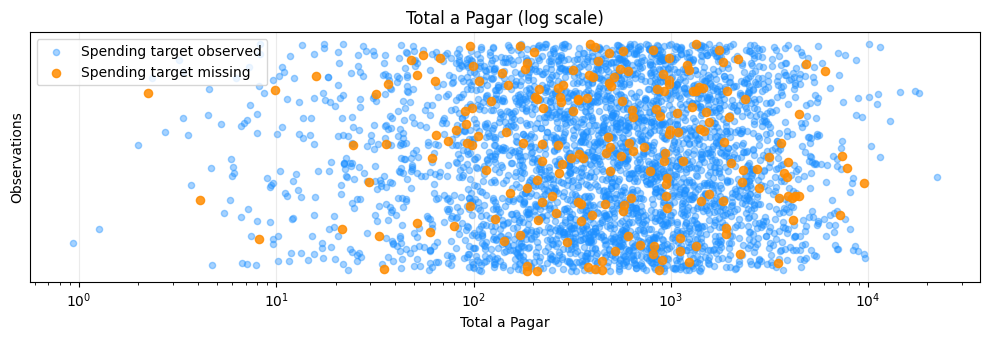

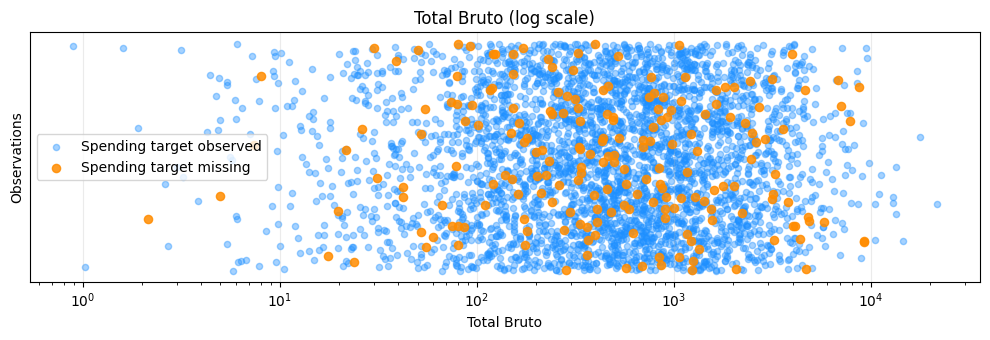

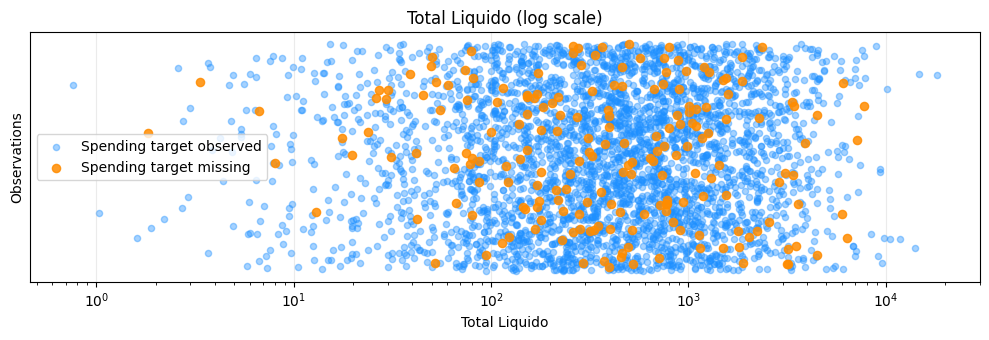

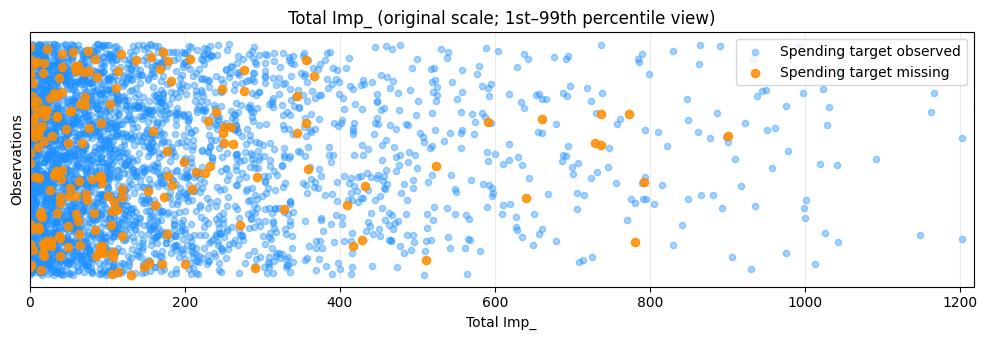

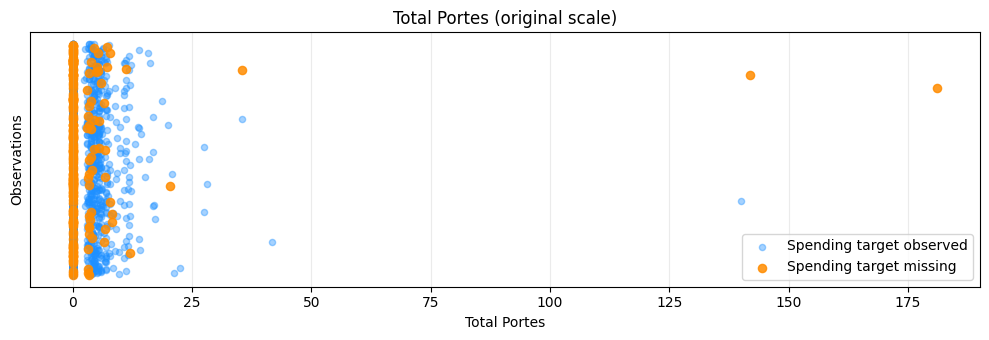

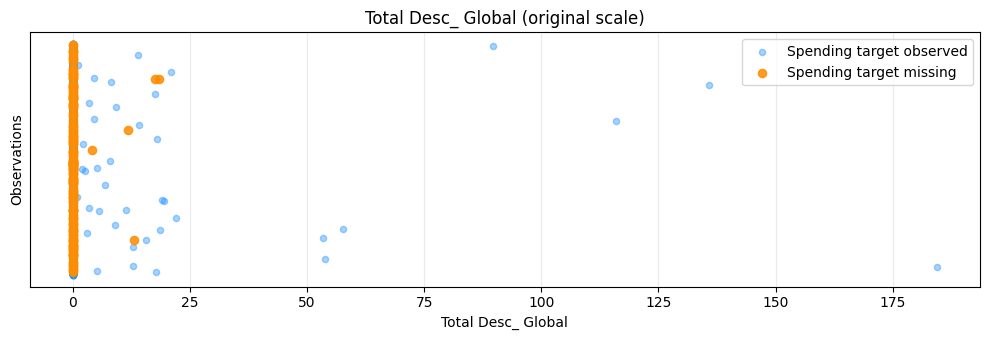

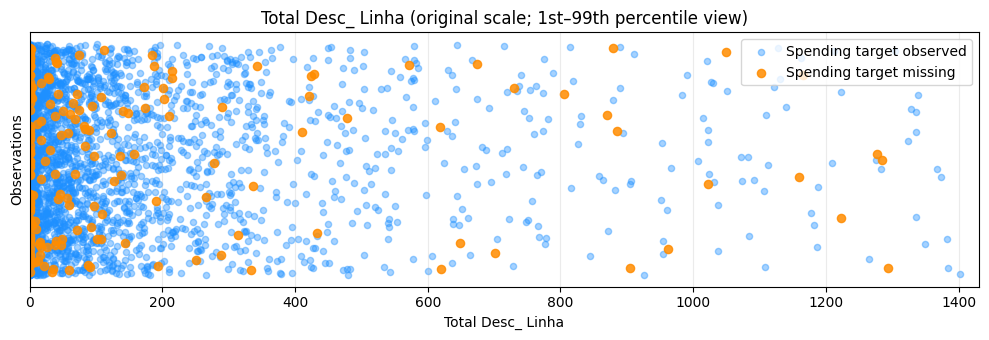

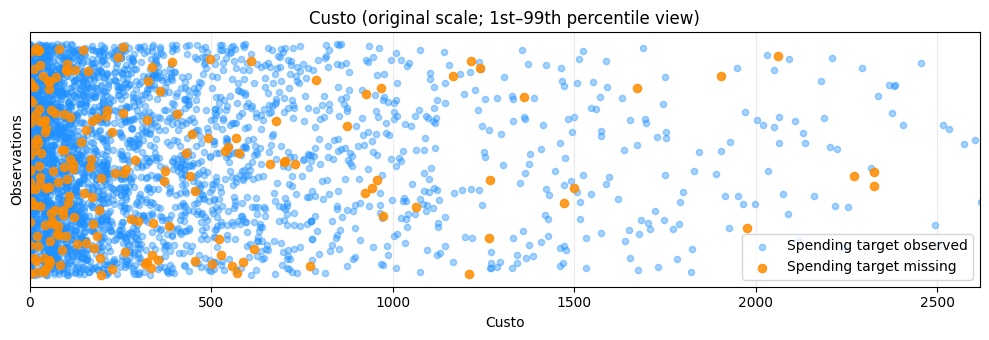

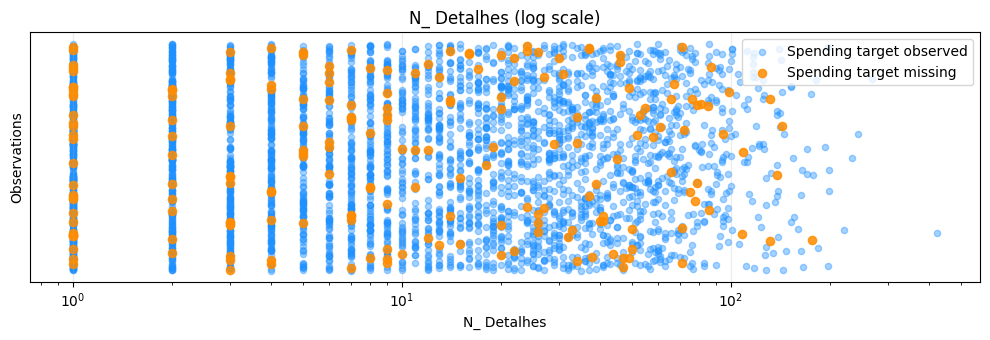

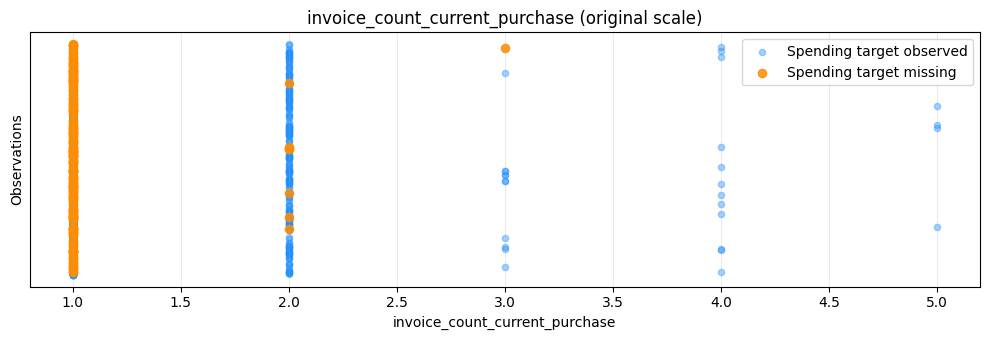

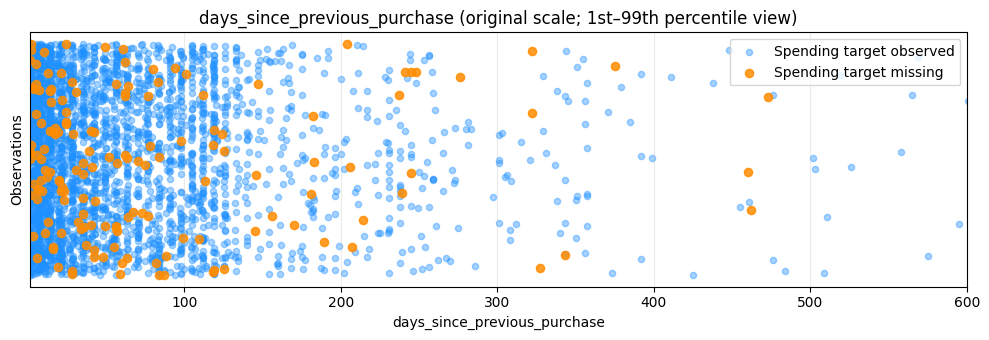

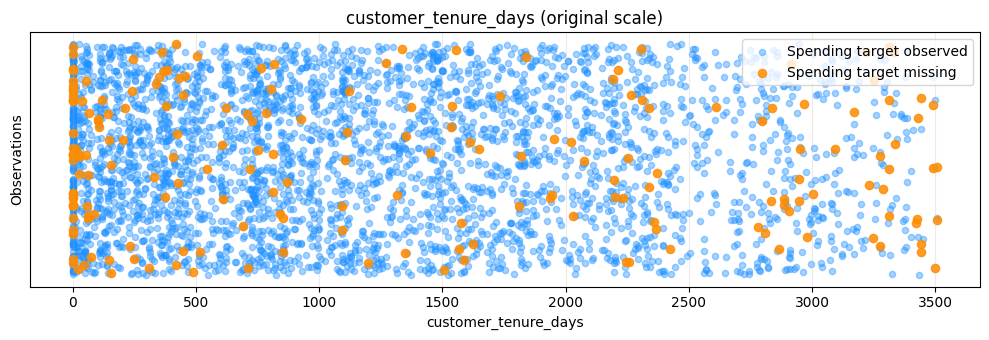

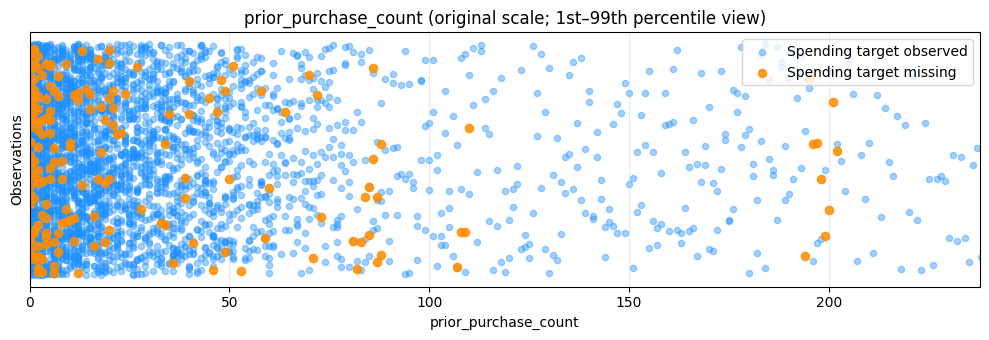

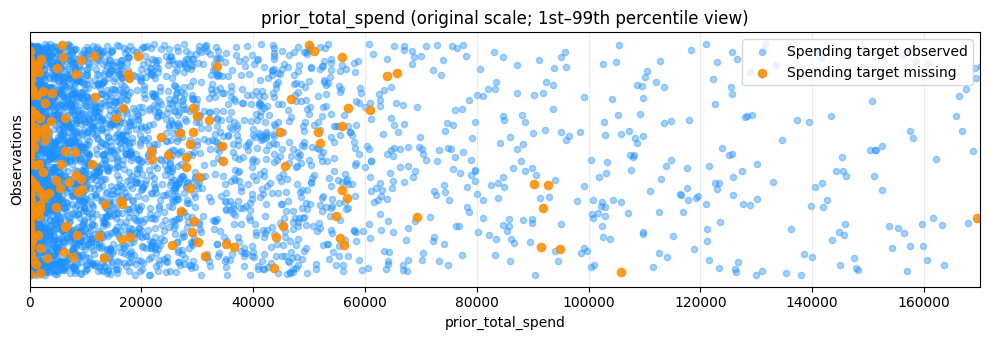

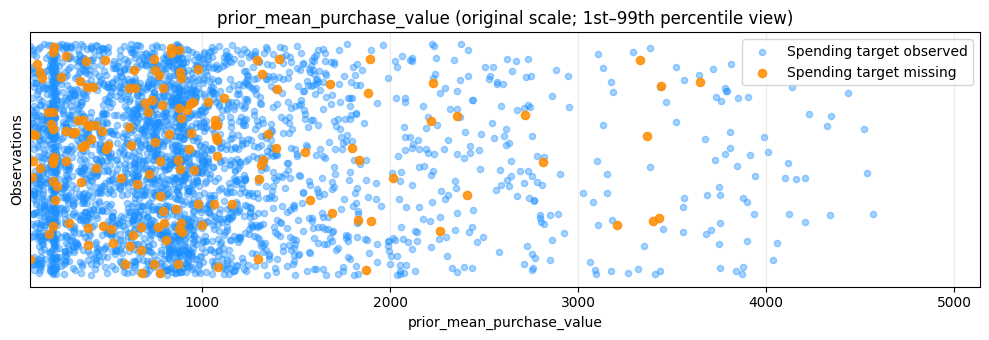

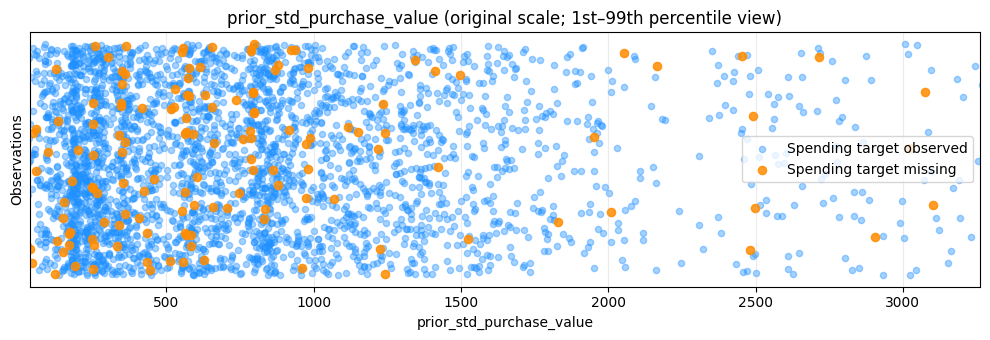

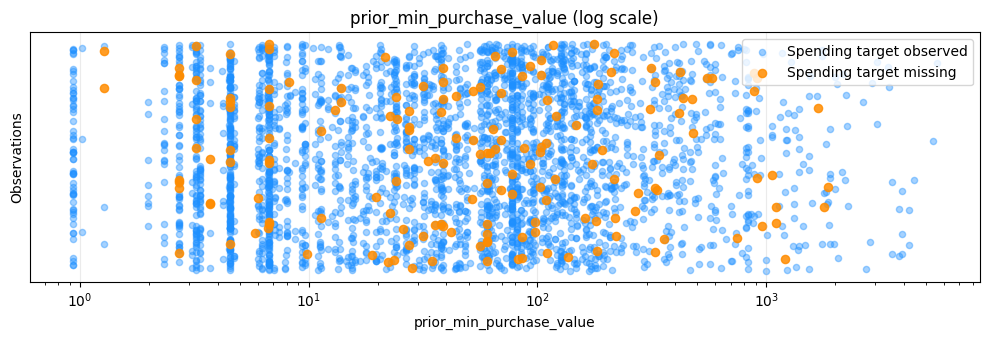

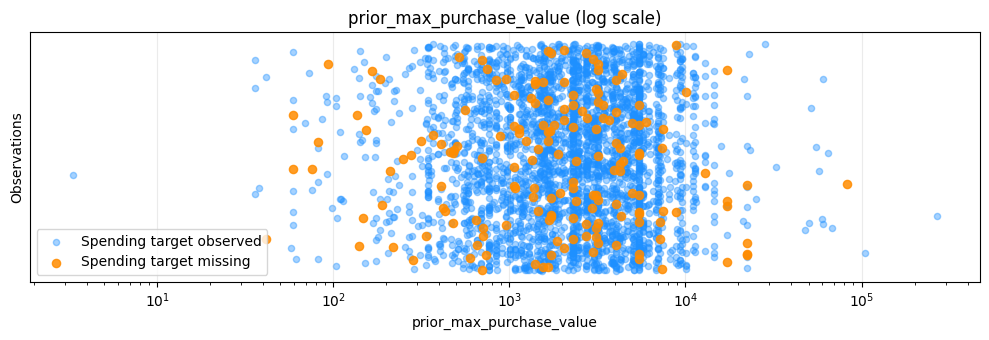

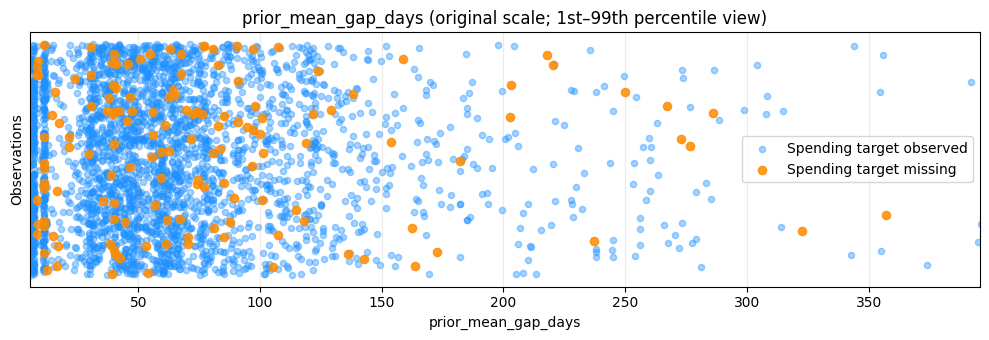

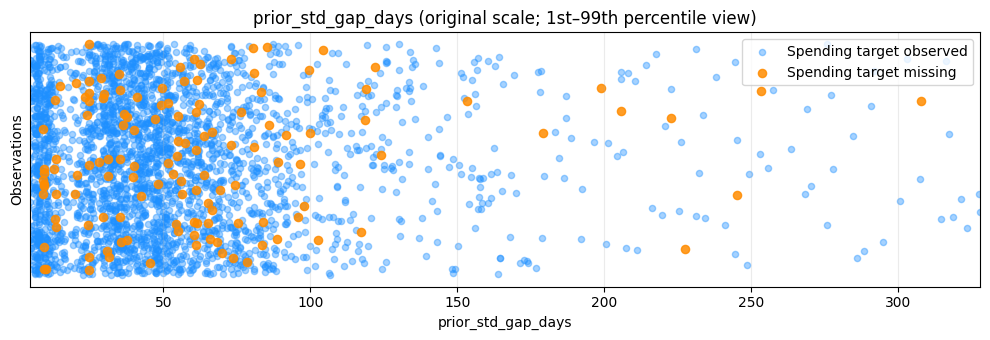

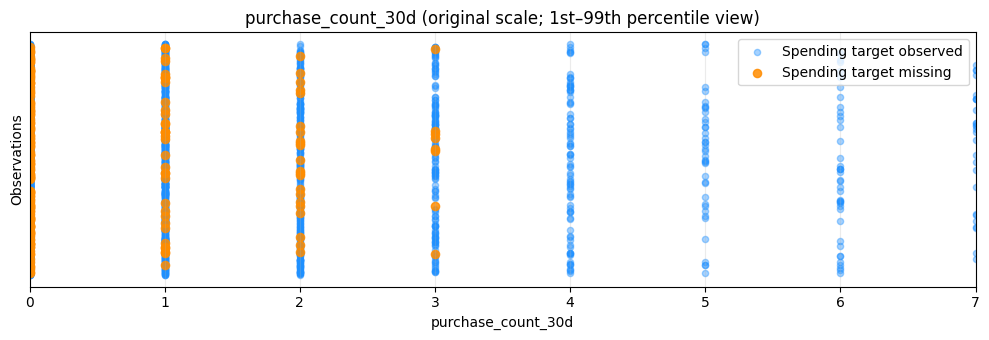

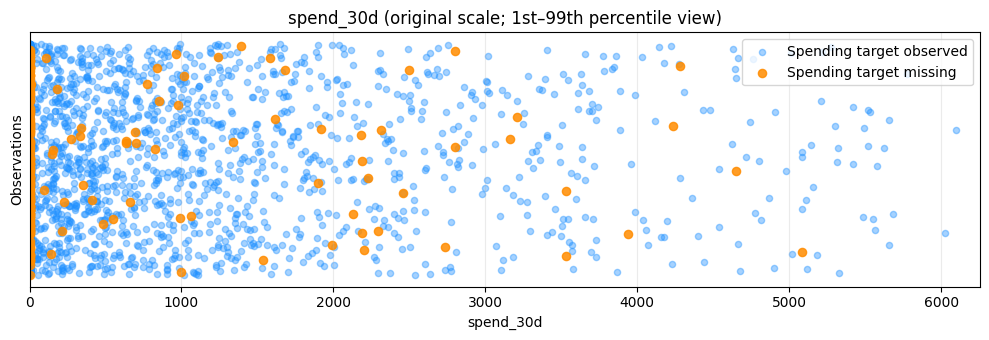

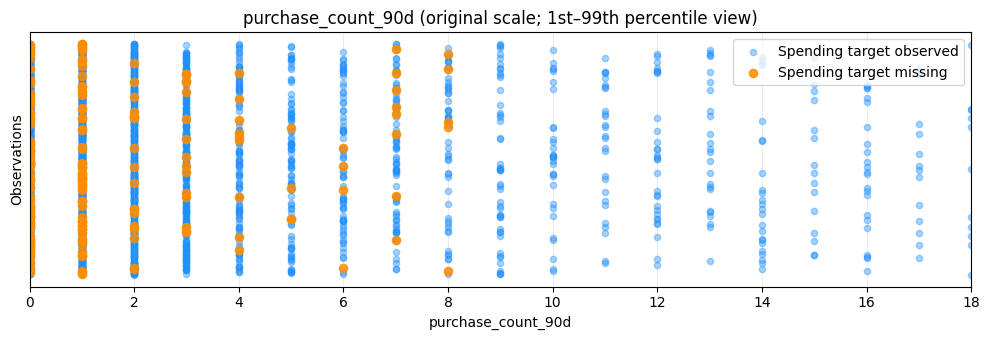

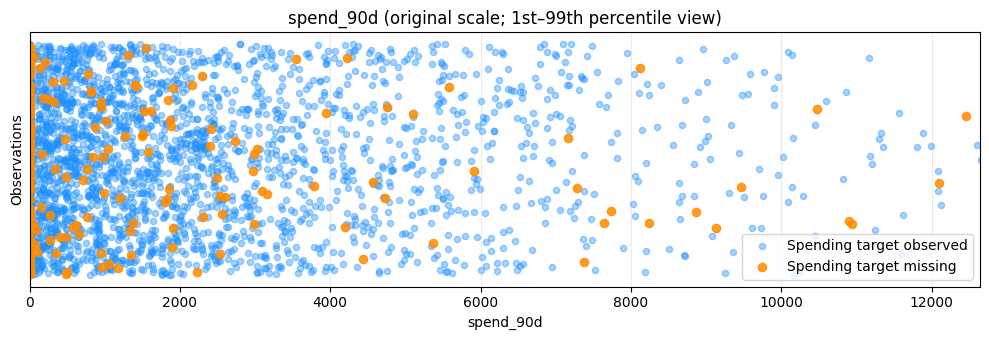

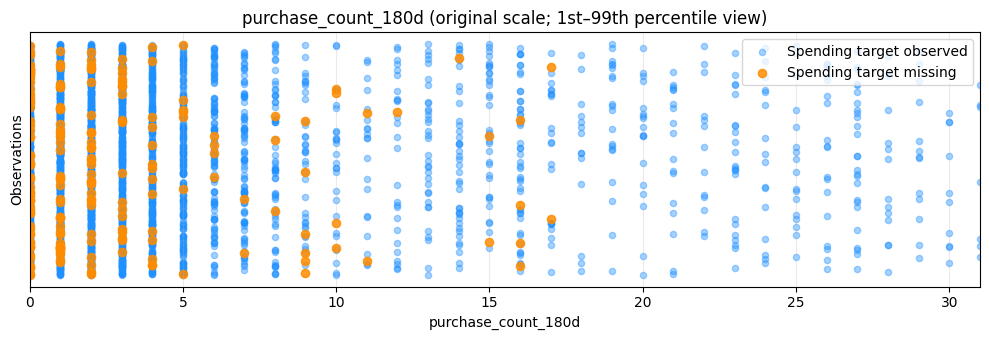

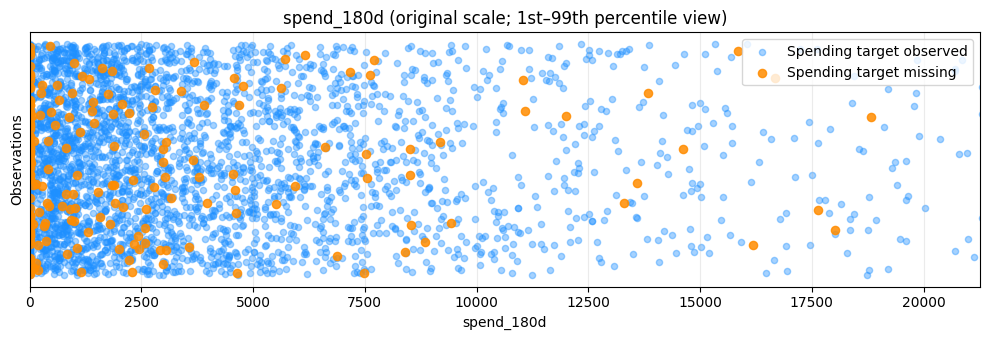

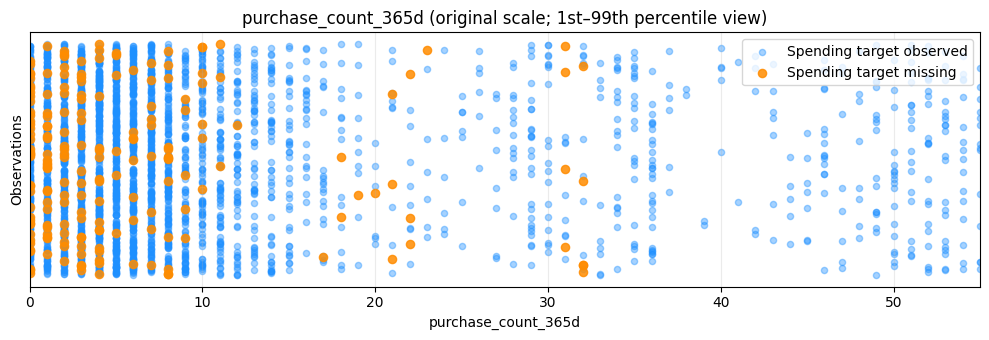

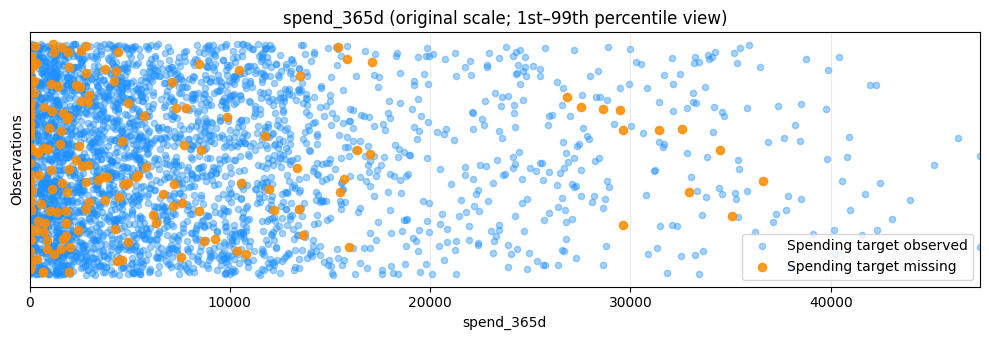

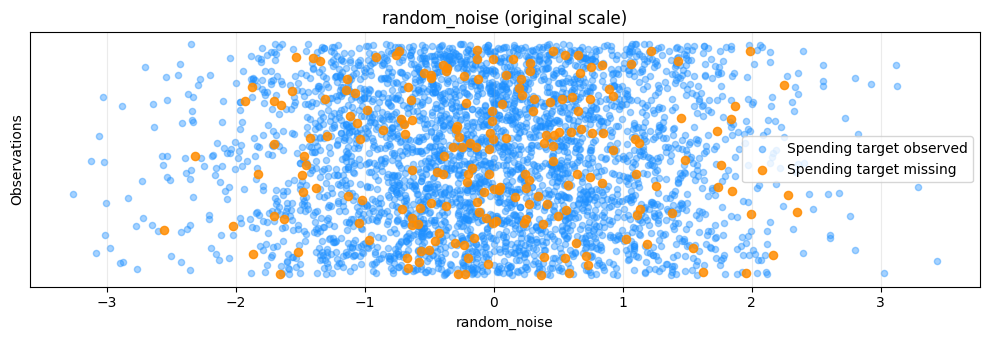

In [26]:

# Focus on repeat purchasers
repeaters = train.loc[
    train["repeat_purchase_90d"] == 1
].copy()

# Identify rows with missing regression targets
missing_target = repeaters["spend_next_90d"].isna()

# Exclude identifiers and target columns from the plots
excluded_cols = [
    "ID",
    "customer_id",
    "repeat_purchase_90d",
    "spend_next_90d",
]

numerical_features = [
    col for col in repeaters.select_dtypes(include="number").columns
    if col not in excluded_cols
]

rng = np.random.default_rng(42)

for feature in numerical_features:

    # Separate observed and missing-target groups
    observed = repeaters.loc[~missing_target, feature].dropna()
    missing = repeaters.loc[missing_target, feature].dropna()

    all_values = pd.concat([observed, missing])

    if all_values.empty:
        continue

    # Determine whether a logarithmic scale is appropriate.
    # Use it only when all observed values are strictly positive
    # and the feature has a sufficiently wide range.
    use_log = (
        (all_values > 0).all()
        and all_values.quantile(0.95) / all_values.quantile(0.05) > 20
        and all_values.quantile(0.05) > 0
    )

    # Create vertical jitter to make overlapping observations visible
    observed_y = rng.uniform(-0.15, 0.15, len(observed))
    missing_y = rng.uniform(-0.15, 0.15, len(missing))

    fig, ax = plt.subplots(figsize=(10, 3.5))

    ax.scatter(
        observed, observed_y,
        color="dodgerblue",
        alpha=0.4,
        s=20,
        label="Spending target observed"
    )

    ax.scatter(
        missing, missing_y,
        color="darkorange",
        alpha=0.85,
        s=35,
        label="Spending target missing"
    )

    if use_log:
        # Log scale helps display values spanning several orders of magnitude
        ax.set_xscale("log")
        scale_description = "log scale"

    else:
        # For features with zero/negative values, preserve the original scale.
        # If extreme values exist, limit the visible axis to the 1st–99th
        # percentiles. This changes only the view, not the underlying data.
        lower = all_values.quantile(0.01)
        upper = all_values.quantile(0.99)

        q1 = all_values.quantile(0.25)
        q3 = all_values.quantile(0.75)
        iqr = q3 - q1

        has_extreme_outliers = (
            iqr > 0
            and (
                all_values.min() < q1 - 3 * iqr
                or all_values.max() > q3 + 3 * iqr
            )
        )

        if has_extreme_outliers and lower < upper:
            ax.set_xlim(lower, upper)
            scale_description = "original scale; 1st–99th percentile view"
        else:
            scale_description = "original scale"

    ax.set_title(f"{feature} ({scale_description})")
    ax.set_xlabel(feature)
    ax.set_yticks([])
    ax.set_ylabel("Observations")
    ax.grid(axis="x", alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()


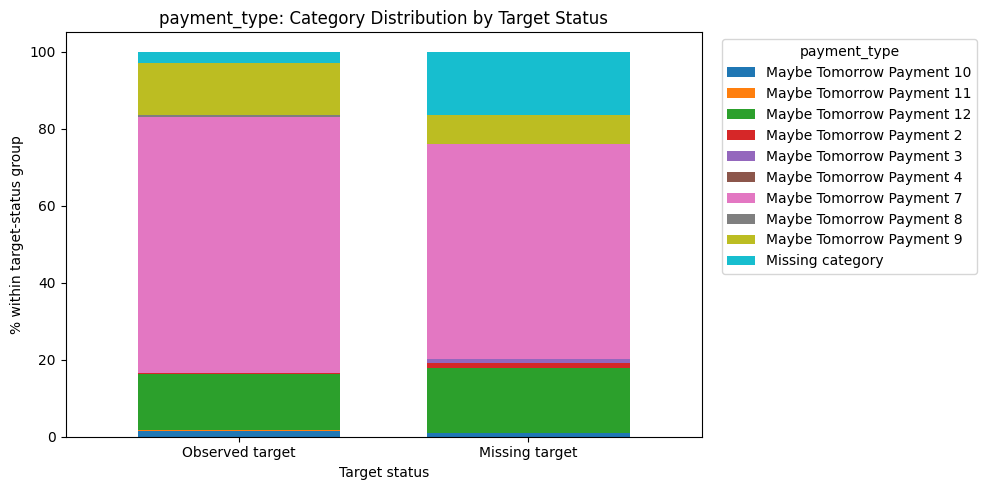

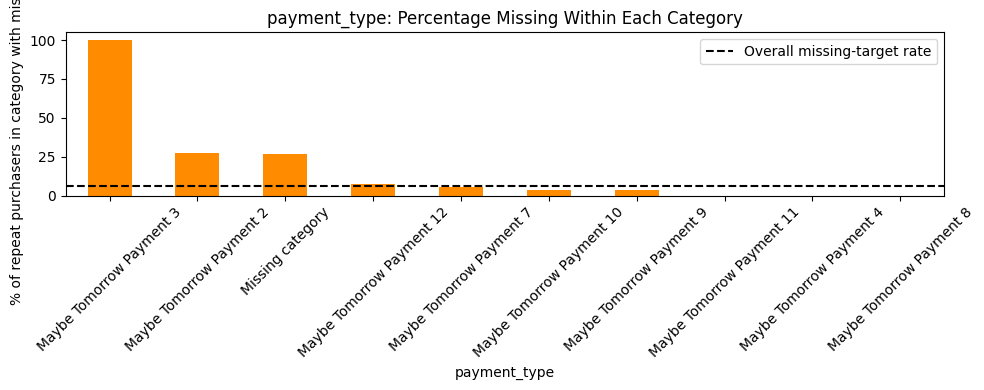

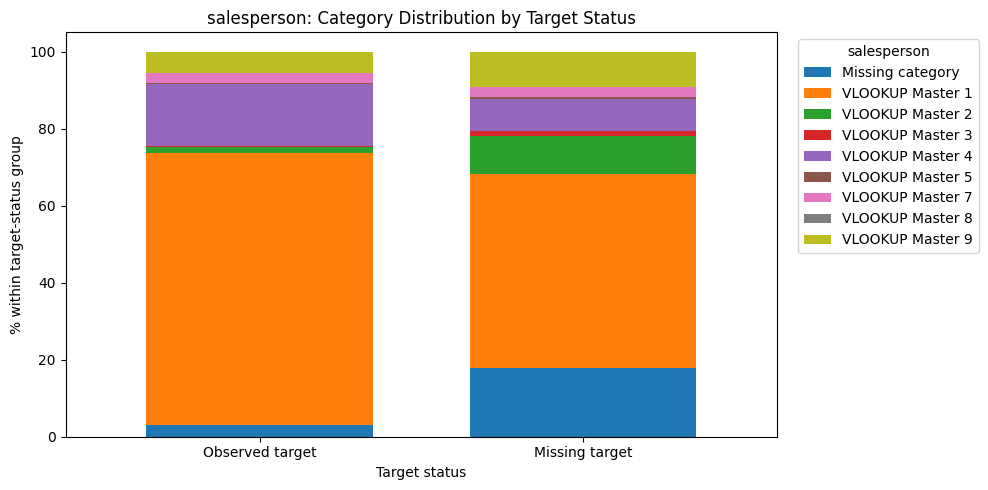

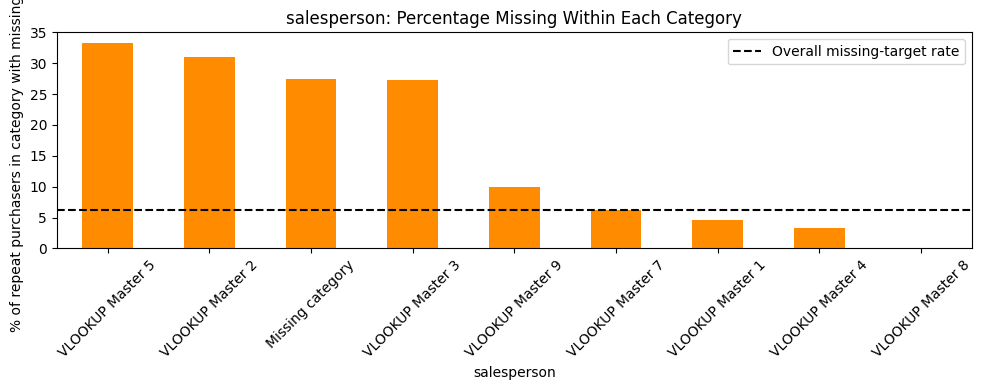

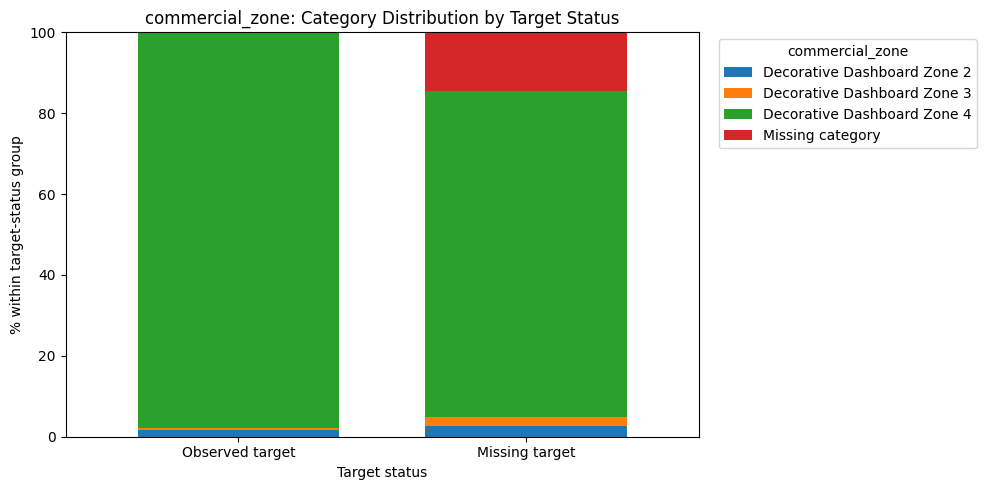

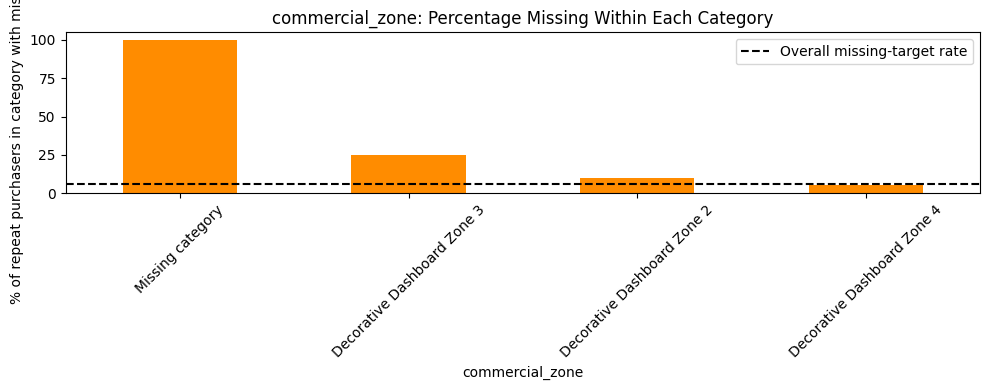

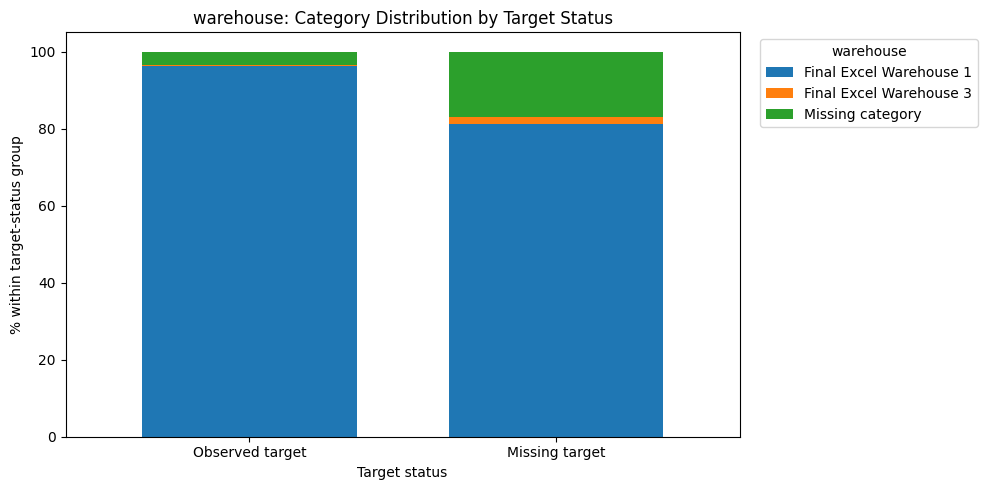

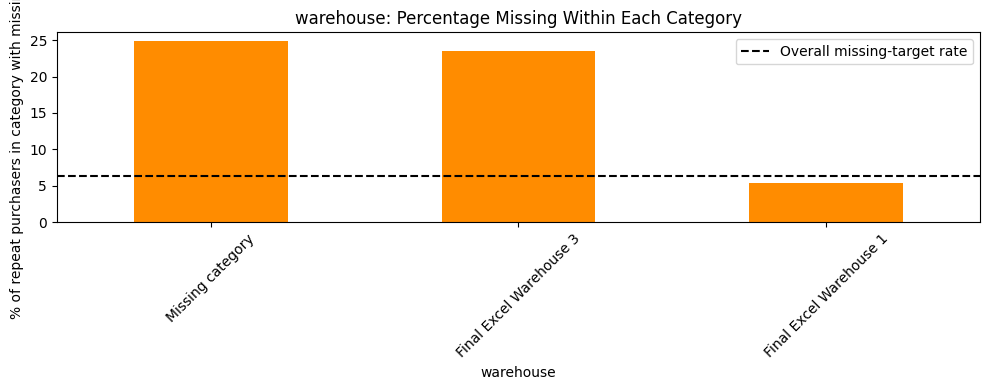

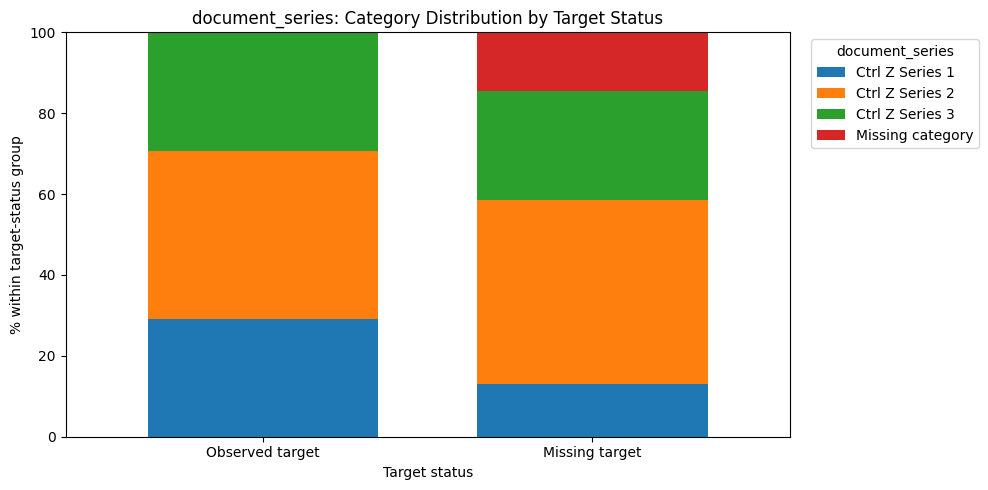

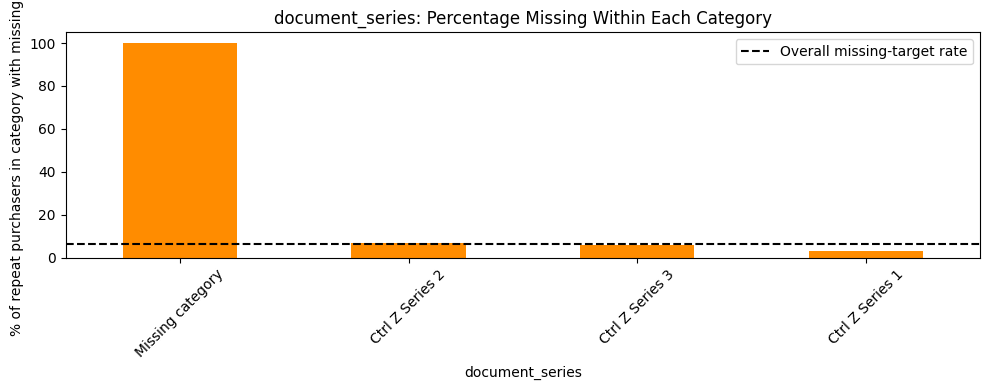

In [27]:

# Focus on repeat purchasers
repeaters = train.loc[
    train["repeat_purchase_90d"] == 1
].copy()

# Identify whether the regression target is missing
repeaters["target_status"] = np.where(
    repeaters["spend_next_90d"].isna(),
    "Missing target",
    "Observed target"
)

# Exclude identifiers and target variables
excluded_cols = [
    "ID",
    "customer_id",
    "repeat_purchase_90d",
    "spend_next_90d",
    "target_status",
    'purchase_date',
    'spend_missing',
    'transport_method',
]

# Identify categorical columns automatically
categorical_features = [
    col for col in repeaters.select_dtypes(
        include=["object", "category", "string"]
    ).columns
    if col not in excluded_cols
]

for feature in categorical_features:

    # Treat missing feature values as a separate category
    data = repeaters[[feature, "target_status"]].copy()
    data[feature] = data[feature].fillna("Missing category").astype(str)

    # Count observations in each category and target-status group
    counts = pd.crosstab(
        data[feature],
        data["target_status"]
    )

    # Ensure both groups appear, even if one has zero observations
    counts = counts.reindex(
        columns=["Observed target", "Missing target"],
        fill_value=0
    )

    # Skip features with no category variation
    if counts.empty:
        continue

    # --------------------------------------------------
    # Plot 1: 100% stacked bars
    # Shows the category distribution within each group
    # --------------------------------------------------
    group_totals = counts.sum(axis=0)
    distribution = counts.div(group_totals.replace(0, np.nan), axis=1) * 100

    ax = distribution.T.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5),
        width=0.7
    )

    ax.set_title(f"{feature}: Category Distribution by Target Status")
    ax.set_xlabel("Target status")
    ax.set_ylabel("% within target-status group")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title=feature, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------
    # Plot 2: Missing-target percentage within each category
    # --------------------------------------------------
    category_totals = counts.sum(axis=1)

    missing_percentage = (
        counts["Missing target"] / category_totals.replace(0, np.nan) * 100
    ).sort_values(ascending=False)

    # Exclude categories with no observations
    missing_percentage = missing_percentage.dropna()

    ax = missing_percentage.plot(
        kind="bar",
        figsize=(10, 4),
        color="darkorange"
    )

    ax.set_title(f"{feature}: Percentage Missing Within Each Category")
    ax.set_xlabel(feature)
    ax.set_ylabel("% of repeat purchasers in category with missing target")
    ax.tick_params(axis="x", rotation=45)
    ax.axhline(
        100 * repeaters["spend_next_90d"].isna().mean(),
        linestyle="--",
        color="black",
        label="Overall missing-target rate"
    )
    ax.legend()
    plt.tight_layout()
    plt.show()


### 2.5 Missing-value treatment decision

- **Broad missingness:** exclude the 65 training rows with a simultaneous, broad predictor-missingness pattern from model fitting. There is no equivalent complete pattern in `test.csv`, and imputation would invent most of a purchase record. Keep the raw rows for audit only.
- **Predictor missingness:** retain the remaining missing feature values until the modelling pipeline. Numeric imputation, categorical `Missing` labels, and missingness indicators must be fitted on each training fold only to avoid leakage.
- **Targets:** never impute either target. The classification target is complete. Train the spend regressor only on repeat purchasers with an observed `spend_next_90d` value.
- **Clientes:** if the optional customer table is merged later, drop `customer_type` because it is entirely missing; handle the other customer fields within the same fold-safe preprocessing pipeline.

In [28]:
assert train_for_classification["repeat_purchase_90d"].notna().all()

repeaters = train_for_classification.loc[
    train_for_classification["repeat_purchase_90d"].eq(1)
].copy()
train_for_regression = repeaters.dropna(subset=["spend_next_90d"]).copy()

print("Classification training rows:", len(train_for_classification))
print("Regression training rows (observed spend only):", len(train_for_regression))
print("Repeat purchasers without an observed spend target:", len(repeaters) - len(train_for_regression))

Classification training rows: 6469
Regression training rows (observed spend only): 3425
Repeat purchasers without an observed spend target: 196


### 2.6 Train/test feature compatibility

The two targets are expected to exist only in `train`. For every predictor shared by train and test, the data type must have the same broad meaning (numeric or text). Exact pandas dtypes may differ because missing numeric values are stored as floats.


In [29]:
target_columns = ["repeat_purchase_90d", "spend_next_90d"]
train_feature_columns = set(train.columns) - set(target_columns)
test_feature_columns = set(test.columns)

print("Features missing from test:", sorted(train_feature_columns - test_feature_columns))
print("Unexpected features in test:", sorted(test_feature_columns - train_feature_columns))

def dtype_family(series):
    return "numeric" if pd.api.types.is_numeric_dtype(series) else "text"

type_report = pd.DataFrame({
    "train_dtype": train.dtypes,
    "test_dtype": test.dtypes,
}).loc[sorted(train_feature_columns & test_feature_columns)]
type_report["train_family"] = [dtype_family(train[column]) for column in type_report.index]
type_report["test_family"] = [dtype_family(test[column]) for column in type_report.index]

display(type_report.query("train_dtype != test_dtype"))
assert train_feature_columns == test_feature_columns
assert type_report["train_family"].equals(type_report["test_family"])


Features missing from test: ['spend_missing']
Unexpected features in test: []


,train_dtype,test_dtype,train_family,test_family
N_ Detalhes,float64,int64,numeric,numeric
customer_tenure_days,float64,int64,numeric,numeric
invoice_count_current_purchase,float64,int64,numeric,numeric
prior_purchase_count,float64,int64,numeric,numeric
purchase_count_180d,float64,int64,numeric,numeric
purchase_count_30d,float64,int64,numeric,numeric
purchase_count_365d,float64,int64,numeric,numeric
purchase_count_90d,float64,int64,numeric,numeric


AssertionError: 

### 2.7 Test categories unseen in training

Some valid test categories do not appear in training. They are not renamed: the later encoder must handle unknown categories safely.


In [ ]:
unseen_category_report = []
for column in categorical_columns:
    train_categories = set(train[column].dropna().astype(str))
    test_categories = set(test[column].dropna().astype(str))
    unseen_in_train = sorted(test_categories - train_categories)
    unseen_category_report.append({
        "column": column,
        "test_categories_unseen_in_train": ", ".join(unseen_in_train) or "None",
    })

unseen_category_report = pd.DataFrame(unseen_category_report)
display(unseen_category_report.query("test_categories_unseen_in_train != 'None'"))


# <font color='#BFD72F' size=6>**3. Validar datas**</font> <a class="anchor" id="1"></a>

- 3.1 **Date validity:** Count missing and unparseable dates in both datasets. Avoid crashes when it contains no valid dates.
- 3.2 **Temporal coverage:** Report the minimum and maximum valid dates for each dataset, with consistent formatting.
- 3.3 **Train/test chronology:** Check whether the training period ends before the test period begins. Report inconsistencies as a warning.
- 3.4 **Temporal distribution:** Check whether dates are concentrated in particular periods and whether there are unexpected gaps, if the data is expected to cover a continuous timeline.

[Back to TOC](#toc)

In [13]:

def validate_purchase_dates(train, test):
    """Validate purchase dates and compare train/test time periods."""

    datasets = {"train": train, "test": test}
    date_col = "purchase_date"
    date_ranges = {}

    # Step 1: Check that both datasets contain the date column.
    for name, df in datasets.items():
        if date_col not in df.columns:
            print(f"ERROR: '{date_col}' is missing from {name}.")
            return

    # Step 2: Parse dates and report invalid or missing values.
    for name, df in datasets.items():
        # Convert invalid date strings to NaT instead of raising errors.
        df[date_col] = pd.to_datetime(
            df[date_col],
            errors="coerce"
        )

        valid_dates = df[date_col].dropna()
        invalid_count = df[date_col].isna().sum()

        print(f"\n--- {name.upper()} DATE VALIDATION ---")
        print(f"Total observations: {len(df)}")
        print(f"Missing/unparseable dates: {invalid_count}")

        # Step 3: Calculate the date interval safely.
        if valid_dates.empty:
            print("No valid dates available.")
            date_ranges[name] = None
            continue

        earliest = valid_dates.min()
        latest = valid_dates.max()

        date_ranges[name] = (earliest, latest)

        print(f"Earliest date: {earliest}")
        print(f"Latest date:   {latest}")

    # Step 4: Compare the temporal coverage of both datasets.
    train_range = date_ranges["train"]
    test_range = date_ranges["test"]

    if train_range is None or test_range is None:
        print("\nCannot compare periods: at least one dataset has no valid dates.")
        return

    train_start, train_end = train_range
    test_start, test_end = test_range

    print("\n--- TRAIN/TEST CHRONOLOGY ---")

    if train_end < test_start:
        print("PASS: Training dates precede test dates.")
    elif test_end < train_start:
        print("WARNING: Test period precedes training period.")
    else:
        print("WARNING: Train/test date ranges overlap.")

        overlap_start = max(train_start, test_start)
        overlap_end = min(train_end, test_end)

        print(f"Overlapping interval: {overlap_start} to {overlap_end}")


# Run date validation.
validate_purchase_dates(train, test)


--- TRAIN DATE VALIDATION ---
Total observations: 6534
Missing/unparseable dates: 65
Earliest date: 2015-07-11 00:00:00
Latest date:   2025-02-15 00:00:00

--- TEST DATE VALIDATION ---
Total observations: 986
Missing/unparseable dates: 0
Earliest date: 2025-05-24 00:00:00
Latest date:   2026-10-06 00:00:00

--- TRAIN/TEST CHRONOLOGY ---
PASS: Training dates precede test dates.


# <font color='#BFD72F' size=6>**4. Duplicates**</font> <a class="anchor" id="1"></a>

- 4.1 Detect exact duplicate rows in each dataset.
- 4.2 Report how many duplicate rows exist and display examples.
- 4.3 **Optionally** remove exact duplicates, keeping the first occurrence.
- 4.4 Check for duplicates across train and test, which can reveal possible data leakage.
- 4.5 **Optionally** check duplicates using specified identifier columns.

[Back to TOC](#toc)

In [14]:
def validate_and_handle_duplicates(
    train,
    test,
    key_cols=None,
    remove_exact=True,
    remove_key_duplicates=False,
    show_examples=True,
    max_examples=10,
):
    """
    Detect and optionally remove duplicates in train and test datasets.

    Parameters
    ----------
    train, test : pandas.DataFrame
        Training and test datasets.
    key_cols : list[str] or None
        Columns that should uniquely identify an observation.
        Examples: ["transaction_id"] or ["customer_id", "purchase_date"].
    remove_exact : bool
        Remove exact duplicate rows within each dataset, keeping the first.
    remove_key_duplicates : bool
        Remove duplicate observations based on key_cols, keeping the first.
        Use only when those columns genuinely identify unique observations.
    show_examples : bool
        Display examples of duplicate rows.
    max_examples : int
        Maximum number of duplicate examples to display.

    Returns
    -------
    train_clean, test_clean : pandas.DataFrame
        Cleaned copies of the original datasets.
    report : dict
        Duplicate counts and cross-dataset diagnostics.
    """

    datasets = {"train": train, "test": test}
    cleaned = {}
    report = {}

    # Step 1: Validate the inputs and key columns.
    if not isinstance(train, pd.DataFrame) or not isinstance(
        test, pd.DataFrame
    ):
        raise TypeError("train and test must be pandas DataFrames.")

    if train.columns.has_duplicates or test.columns.has_duplicates:
        raise ValueError("Duplicate column names must be resolved first.")

    if key_cols is not None:
        if isinstance(key_cols, str):
            key_cols = [key_cols]
        else:
            key_cols = list(key_cols)

        if not key_cols:
            raise ValueError("key_cols cannot be an empty list.")

        for name, df in datasets.items():
            missing_cols = set(key_cols) - set(df.columns)
            if missing_cols:
                raise ValueError(
                    f"{name} is missing key columns: {sorted(missing_cols)}"
                )

    # Step 2: Inspect and optionally remove duplicates within each dataset.
    for name, df in datasets.items():
        result = df.copy()

        # Detect exact duplicate rows, excluding the first occurrence.
        exact_mask = result.duplicated(keep="first")
        exact_count = int(exact_mask.sum())

        print(f"\n--- {name.upper()} DUPLICATE VALIDATION ---")
        print(f"Original rows: {len(result)}")
        print(f"Exact duplicate rows: {exact_count}")

        if show_examples and exact_count > 0:
            print("Examples of exact duplicates:")
            display(result.loc[exact_mask].head(max_examples))

        # Optionally remove exact duplicate rows.
        if remove_exact:
            result = result.drop_duplicates(keep="first")

        key_report = None

        # Step 3: Check duplicates based on the chosen observation key.
        if key_cols is not None:
            # Rows with incomplete keys cannot be reliably matched.
            complete_key_mask = result[key_cols].notna().all(axis=1)
            incomplete_key_count = int((~complete_key_mask).sum())

            # Only evaluate uniqueness among rows with complete keys.
            complete_rows = result.loc[complete_key_mask]
            key_duplicate_mask = complete_rows.duplicated(
                subset=key_cols,
                keep="first",
            )
            key_duplicate_count = int(key_duplicate_mask.sum())

            print(f"Rows with incomplete keys: {incomplete_key_count}")
            print(f"Duplicate key rows: {key_duplicate_count}")

            if show_examples and key_duplicate_count > 0:
                print(f"Examples of duplicate keys ({key_cols}):")
                display(
                    complete_rows.loc[key_duplicate_mask]
                    .head(max_examples)
                )

            # Remove duplicate keys only when explicitly requested.
            if remove_key_duplicates:
                duplicate_index = complete_rows.index[key_duplicate_mask]
                result = result.drop(index=duplicate_index)

            key_report = {
                "key_columns": key_cols,
                "incomplete_key_rows": incomplete_key_count,
                "duplicate_key_rows": key_duplicate_count,
            }

        cleaned[name] = result

        report[name] = {
            "original_rows": len(df),
            "exact_duplicate_rows": exact_count,
            "rows_after_exact_deduplication": (
                len(df.drop_duplicates()) if remove_exact else len(df)
            ),
            "final_rows": len(result),
            "key_diagnostics": key_report,
        }

        print(f"Rows after handling duplicates: {len(result)}")

    # Step 4: Check for exact row matches between train and test.
    # This is diagnostic only: do not automatically remove test rows.
    train_clean = cleaned["train"]
    test_clean = cleaned["test"]

    common_cols = list(
        col for col in train_clean.columns
        if col in test_clean.columns
    )

    if not common_cols:
        print("\nCannot compare train/test rows: no shared columns.")
        cross_exact_count = None
    else:
        # Hash corresponding shared-column values consistently.
        # Hashes allow comparison without a potentially large DataFrame merge.
        train_hashes = pd.util.hash_pandas_object(
            train_clean[common_cols], index=False
        )
        test_hashes = pd.util.hash_pandas_object(
            test_clean[common_cols], index=False
        )

        train_hash_set = set(train_hashes)
        cross_exact_count = int(test_hashes.isin(train_hash_set).sum())

        print("\n--- TRAIN/TEST OVERLAP ---")
        print(
            "Test rows matching a train row on shared columns:",
            cross_exact_count,
        )

        if set(train_clean.columns) != set(test_clean.columns):
            print(
                "WARNING: Cross-dataset comparison uses shared columns only; "
                "matches are not necessarily identical full observations."
            )
        else:
            print(
                "Note: Matching rows are flagged for investigation, "
                "not automatically removed."
            )

    report["cross_dataset"] = {
        "shared_columns": common_cols,
        "matching_test_rows": cross_exact_count,
    }

    return train_clean, test_clean, report


In [15]:
train_clean, test_clean, duplicate_report = (
    validate_and_handle_duplicates(
        train,
        test,
        key_cols=["ID"],
        remove_exact=True,
        remove_key_duplicates=False,
    )
)


--- TRAIN DUPLICATE VALIDATION ---
Original rows: 6534
Exact duplicate rows: 0
Rows with incomplete keys: 0
Duplicate key rows: 0
Rows after handling duplicates: 6534

--- TEST DUPLICATE VALIDATION ---
Original rows: 986
Exact duplicate rows: 0
Rows with incomplete keys: 0
Duplicate key rows: 0
Rows after handling duplicates: 986

--- TRAIN/TEST OVERLAP ---
Test rows matching a train row on shared columns: 0
